# Load the same RSML and Ariadne NX

In [1]:
from pathlib import Path
from pprint import pprint
from openalea.widgets.mtg import plot as plot_mtg
from openalea import rsml
%run read.py

## Load the data

Each file represent the 2D+t root topology of 5 arabidopsis plants

In [2]:
from pathlib import Path
from pprint import pprint

data = Path('data')/'RSML_03_2026'/'261301MB04'
rsa_files = list(data.glob('61_graph_expertized.rsml'))
pprint(rsa_files)

[PosixPath('data/RSML_03_2026/261301MB04/61_graph_expertized.rsml')]


In [3]:
fn = rsa_files[0]
g = convert_fine_mtg(fn)
# Split the forest into 5 independent graphs
g1, g2, g3, g4, g5 = gs =  split(g)


In [4]:
ts = times(g1)
x = g1.property('x')
y = g1.property('y')
print(f'bbox : ({min(x), min(y)}), ({max(x), max(y)})')
ts

bbox : ((2, 2)), ((439, 439))


[0.0,
 0.0301,
 0.0796,
 0.2962,
 0.342,
 0.431,
 0.5042,
 0.5884,
 0.6054,
 0.7196,
 0.79,
 0.814,
 0.831,
 0.8731,
 0.9189,
 0.949,
 1.0,
 1.1994,
 1.5872,
 1.8237,
 2.0,
 2.7952,
 3.0,
 3.2699,
 3.5364,
 4.0,
 4.0906,
 4.1268,
 4.3449,
 4.4355,
 4.6533,
 4.7257,
 4.9819,
 5.0,
 5.7797,
 6.0,
 6.1061,
 6.3562,
 6.807,
 7.0,
 7.2071,
 7.8619,
 8.0,
 8.1829,
 8.2612,
 8.6567,
 9.0,
 9.2279,
 9.2632,
 9.3735,
 9.6011,
 9.6796,
 9.7094,
 10.0,
 10.2638,
 10.3065,
 10.5168,
 10.6519,
 10.9157,
 11.0,
 11.4631,
 11.5279,
 11.5618,
 11.7502,
 11.8569,
 12.0,
 12.1671,
 12.2432,
 12.3764,
 12.5228,
 12.6633,
 12.9046,
 13.0,
 13.1668,
 13.2249,
 13.3372,
 13.4383,
 13.5279,
 13.5953,
 13.6126,
 13.9289,
 13.9612,
 14.0,
 14.3215,
 14.3711,
 14.5147,
 14.515,
 14.5259,
 14.6385,
 14.6733,
 14.7094,
 14.8454,
 14.8592,
 15.0,
 15.2409,
 15.3176,
 15.5205,
 15.7222,
 15.8801,
 16.0,
 16.1207,
 16.1239,
 16.1929,
 16.3431,
 16.4193,
 16.6442,
 16.6501,
 16.7892,
 16.8002,
 16.8551,
 16.8933,
 17

In [5]:
# Convert all the graphs into NetworkX DAG
dgs = [mtg2nx(g) for g in gs]
dg1, dg2, dg3, dg4, dg5 = dgs

In [6]:
dg3.nodes[0]

{'x': 577.0,
 'y': 187.0,
 'time': 0.0,
 'time_hours': 0.0,
 'label': 'Segment',
 'diameter': 0.0,
 'root_deg': 0,
 'LR_index': None,
 'pos': [0.0, 0.0]}

------------------

## Load data from Ariadne

In [7]:
%run read.py
data2 = Path('data')/'RSML_NX_Root'
rsa_files = list(data2.glob('20262101*_Boite*04*.json'))
rsa_files.sort()
pprint(rsa_files)


[PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantA_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantB_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantC_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantD_day22.json'),
 PosixPath('data/RSML_NX_Root/20262101-DRUGS_BR_2.1_Seq1_Boite00004_IdentificationFailed_plantE_day22.json')]


In [8]:
# Convert all the graphs into NetworkX DAG
nxgs = [json2nx(fn) for fn in rsa_files]

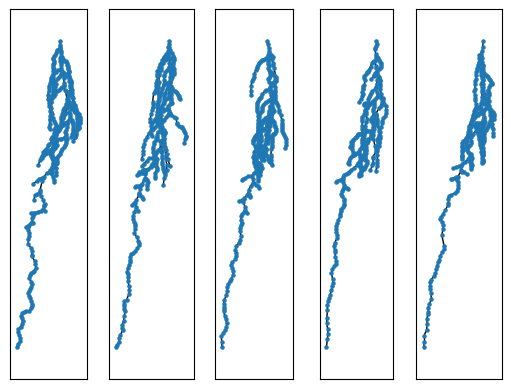

In [9]:
fig, axes = plt.subplots(1,5)
for i in range(5):
    plot_mpl(nxgs[i], ax=axes[i])

## Compare RSML (dgs) and Ariadne (nxgs)

In [10]:
dgs[0].nodes[0]

{'x': 162.0,
 'y': 197.0,
 'time': 0.0,
 'time_hours': 0.0,
 'label': 'Segment',
 'diameter': 0.0,
 'root_deg': 0,
 'LR_index': None,
 'pos': [0.0, 0.0]}

In [11]:
g00, g01 = dgs[0], nxgs[0]

In [12]:
r0,alphas,random_a=analyze_with_ariadne_graph(g00)
r1,_,_=analyze_with_ariadne_graph(g01)


[(0.0, [9247.205946857071, 9247.205946857071]), (0.01, [2255.013710067057, 9262.750126839497]), (0.02, [1882.049689054732, 9287.766252775895]), (0.03, [1750.59543706563, 9298.956613352168]), (0.04, [1617.7643631888734, 9308.607698803498])]
[(0.0, [33365.61722201834, 33365.61722201834]), (0.01, [7905.151588422797, 33452.57529257472]), (0.02, [7072.618902428254, 33492.31734951487]), (0.03, [6524.968222098794, 33521.401276563825]), (0.04, [6597.409302686032, 33526.592917593196])]


In [13]:
names = list(r0)
for name in names:
    try:
        diff = r0[name]-r1[name]
        if abs(diff) >0.1:
            #print(f'Error in {name}:\n R0:{r0[name]}, R1:{r1[name]}')
            #print(f'Ratio : {r1[name]/r0[name]}')
            pass
    except: pass

In [14]:
gm0=nx2mtg(g00)
gm1=nx2mtg(g01)


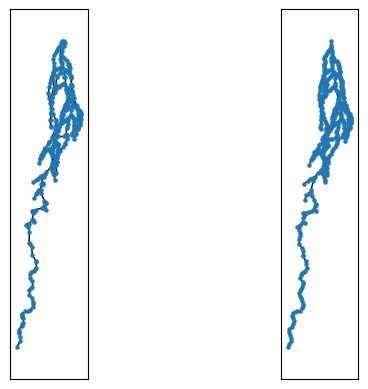

In [15]:
fig, axes = plt.subplots(1,2)
plot_mpl_mtg(gm0, ax=axes[0])
plot_mpl_mtg(gm1, ax=axes[1])

In [16]:
print(f'nb vertices RSML: {len(gm0)}')
print(f'nb vertices Nx: {len(gm1)}')



nb vertices RSML: 414
nb vertices Nx: 434


In [17]:
pos0 = list(v for k, v in g00.nodes('pos'))
pos1 = list(v for k, v in g01.nodes('pos'))

In [18]:
def minmax(pos):
    x_min = min(p[0] for p in pos)
    x_max = max(p[0] for p in pos)
    y_min = min(p[1] for p in pos)
    y_max = max(p[1] for p in pos)
    return (x_min, x_max), (y_min, y_max)

print(minmax(pos0))
print(minmax(pos1))



((-123.0, 51.0), (0.0, 823.0))
((-476.0, 219.0), (0, 3332.0))


In [19]:
def scaling(g1, g2):
    pos1 = list(v for k, v in g1.nodes('pos'))
    pos2 = list(v for k, v in g2.nodes('pos'))

    (x1_min, x1_max), (y1_min, y1_max) = minmax(pos1)
    (x2_min, x2_max), (y2_min, y2_max) = minmax(pos2)

    dx1 = x1_max - x1_min
    dx2 = x2_max - x2_min
    dy1 = y1_max - y1_min
    dy2 = y2_max - y2_min

    r1 = dx2 / dx1
    r1 = round(r1)
    r2 = dy2 / dy1
    r2 = round(r2)

    print(dx1, dx2, dy1, dy2)
    return r1, r2


In [27]:
g00, g01 = dgs[0], nxgs[0]
print(scaling(g00, g01))


174.0 695.0 823.0 3332.0
(4, 4)


3292

In [28]:
def resolution(nxg, unit_cm=1, scale=1/4.):

    for i,pos in nxg.nodes(data='pos'):
        x,y = pos
        nxg.nodes()[i]['pos'] = [x*unit_cm*scale, y*unit_cm*scale]

    return nxg


In [29]:
#g00 = resolution(g00, unit_cm=1/460, scale=4)

In [30]:
g01 = resolution(g01, unit_cm=1, scale=1/4)

In [31]:
r0,alphas,random_a=analyze_with_ariadne_graph(g00)
r1,_,_=analyze_with_ariadne_graph(g01)


[(0.0, [9247.205946857071, 9247.205946857071]), (0.01, [2255.013710067057, 9262.750126839497]), (0.02, [1882.049689054732, 9287.766252775895]), (0.03, [1750.59543706563, 9298.956613352168]), (0.04, [1617.7643631888734, 9308.607698803498])]
[(0.0, [8341.404305504586, 8341.404305504586]), (0.01, [1976.2878971056994, 8363.14382314368]), (0.02, [1768.1547256070635, 8373.079337378718]), (0.03, [1631.2420555246986, 8380.350319140956]), (0.04, [1649.352325671508, 8381.648229398299])]


In [34]:
def compare(g00, g01):
    r0,alphas,random_a=analyze_with_ariadne_graph(g00)
    r1,_,_=analyze_with_ariadne_graph(g01)
    names = list(r0)
    for name in names:
        try:
            diff = r0[name]-r1[name]
            if abs(diff) >1000:
                print(f'Error in {name}:\n R0:{r0[name]}, R1:{r1[name]}')
                print(f'Ratio : {r1[name]/r0[name]}')
        except: pass

In [35]:
compare(g00, g01)

[(0.0, [9247.205946857071, 9247.205946857071]), (0.01, [2255.013710067057, 9262.750126839497]), (0.02, [1882.049689054732, 9287.766252775895]), (0.03, [1750.59543706563, 9298.956613352168]), (0.04, [1617.7643631888734, 9308.607698803498])]
[(0.0, [8341.404305504586, 8341.404305504586]), (0.01, [1976.2878971056994, 8363.14382314368]), (0.02, [1768.1547256070635, 8373.079337378718]), (0.03, [1631.2420555246986, 8380.350319140956]), (0.04, [1649.352325671508, 8381.648229398299])]
Error in Travel distance:
 R0:10371.411066170192, R1:9286.91531255733
Ratio : 0.8954341172388485
Error in Travel distance (random):
 R0:21610.325422909602, R1:19485.94723357468
Ratio : 0.9016961499763988


In [36]:
r0,alphas,random_a=analyze_with_ariadne_graph(g00)
r1,alphas,random_a=analyze_with_ariadne_graph(g01)


[(0.0, [9247.205946857071, 9247.205946857071]), (0.01, [2255.013710067057, 9262.750126839497]), (0.02, [1882.049689054732, 9287.766252775895]), (0.03, [1750.59543706563, 9298.956613352168]), (0.04, [1617.7643631888734, 9308.607698803498])]
[(0.0, [8341.404305504586, 8341.404305504586]), (0.01, [1976.2878971056994, 8363.14382314368]), (0.02, [1768.1547256070635, 8373.079337378718]), (0.03, [1631.2420555246986, 8380.350319140956]), (0.04, [1649.352325671508, 8381.648229398299])]


In [37]:
r0['PR length']- r1['PR length']

-15.080490174563352

## TODO
- Write the RSML scaling directly in the reader or just after
- generate the csv from the analysis